In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression

In [8]:
pip install ucimlrepo


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:

from ucimlrepo import fetch_ucirepo 
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
# metadata 
print(heart_disease.metadata) 
# variable information 
print(heart_disease.variables) 

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [10]:
print(heart_disease.variables)

        name     role         type demographic  \
0        age  Feature      Integer         Age   
1        sex  Feature  Categorical         Sex   
2         cp  Feature  Categorical         NaN   
3   trestbps  Feature      Integer         NaN   
4       chol  Feature      Integer         NaN   
5        fbs  Feature  Categorical         NaN   
6    restecg  Feature  Categorical         NaN   
7    thalach  Feature      Integer         NaN   
8      exang  Feature  Categorical         NaN   
9    oldpeak  Feature      Integer         NaN   
10     slope  Feature  Categorical         NaN   
11        ca  Feature      Integer         NaN   
12      thal  Feature  Categorical         NaN   
13       num   Target      Integer         NaN   

                                          description  units missing_values  
0                                                 NaN  years             no  
1                                                 NaN    NaN             no  
2              

In [11]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [12]:
print("Linhas com algum faltante:")
display(X[X.isna().any(axis=1)])


Linhas com algum faltante:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0


In [13]:
from sklearn.impute import SimpleImputer

imp = SimpleImputer(strategy="median")
imp.fit(X)
Ximp = imp.transform(X)

In [14]:
Ximpdf = pd.DataFrame(Ximp, columns=X.columns, index=X.index)
display(Ximpdf.isna().sum())
X = Ximpdf

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

In [15]:
y_bin = (y > 0).astype(int)
print(y_bin.value_counts())

num
0      164
1      139
Name: count, dtype: int64


In [16]:
print(y.value_counts())

num
0      164
1       55
2       36
3       35
4       13
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
  X, y_bin, test_size=0.2, random_state=42
)

print(f"Tamanho do dataset = {X.shape[0]} amostras")
print(f"Quantidade de amostras de treinamento = {X_train.shape[0]} amostras")
print(f"Quantidade de amostras de teste = {X_test.shape[0]} amostras")

Tamanho do dataset = 303 amostras
Quantidade de amostras de treinamento = 242 amostras
Quantidade de amostras de teste = 61 amostras


In [18]:
from sklearn.preprocessing import StandardScaler
 
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [19]:
model = LogisticRegression(solver="liblinear", random_state=42, max_iter=1000)
model.fit(X_train_s, y_train.values.ravel())
print(f"Iterações até a convergência: {model.n_iter_[0]}")

Iterações até a convergência: 6


In [20]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)
y_pred = model.predict(X_test_s)
y_proba = model.predict_proba(X_test_s)[:, 1]


print(f'Acurácia: {accuracy_score(y_test, y_pred):.4f}')
print(f'Precisão: {precision_score(y_test, y_pred):.4f}')
print(f'Recall: {recall_score(y_test, y_pred):.4f}')
print(f'F1-score: {f1_score(y_test, y_pred):.4f}')


Acurácia: 0.8852
Precisão: 0.8788
Recall: 0.9062
F1-score: 0.8923


AUC: 0.9213


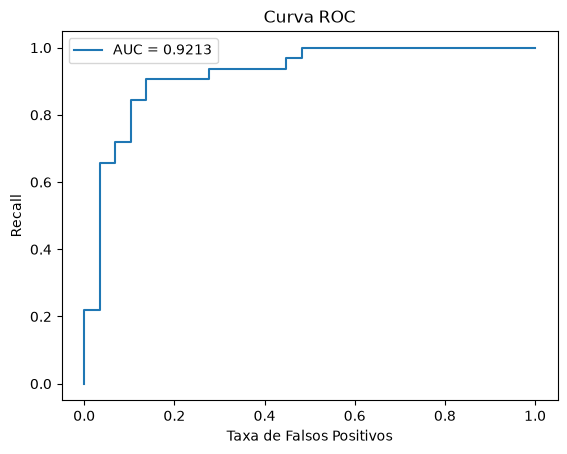

In [21]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

print(f'AUC: {auc:.4f}')

plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Recall')
plt.title('Curva ROC')
plt.legend()
plt.show()

A acurácia de 88,5% mostra que o modelo acerta o diagnóstico em cerca de 8 de cada 10 pacientes. A precisão de 87,8% significa que, quando o modelo aponta doença cardíaca, ele está certo em quase 88% dos casos. O recall de 90,6% significa que o modelo identifica a grande maioria dos pacientes que realmente têm a doença. O F1-score de 0,892 que os valores de precisão e recall estão balanceados.
O recall ligeiramente superior à precisão é desejável neste contexto, pois é mais grave deixar de detectar um paciente doente (falso negativo) do que encaminhar um saudável para exames adicionais (falso positivo).